# LightGBM — tuning, evaluation and test on 4 targets
Targets: **Cath** (overall CAD), **LAD**, **LCX**, **RCA**. Input: `data/processed/cad_clean.csv` produced by notebook 01 (frozen 80/20 stratified split).

Workflow: baseline → complexity / depth sweeps → feature-count sweep → GridSearchCV → RandomizedSearchCV → CV-fold study → nested CV (paper-comparable protocol) → threshold tuning → **single** test evaluation → paper methods (single / OR-rule / stacked) → permutation importance → save.

All scaling, encoding, feature selection and SMOTE sit inside one `imblearn` `Pipeline`, so every CV fold is leak-free. LAD/LCX/RCA/Cath are never inputs, except as *out-of-fold* probabilities in the paper's stacked method.

## 0. Setup

In [1]:
import warnings; warnings.filterwarnings('ignore')
import time
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, joblib
from scipy.stats import loguniform, randint, uniform
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder, FunctionTransformer
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.model_selection import (StratifiedKFold, RepeatedStratifiedKFold, GridSearchCV, RandomizedSearchCV,
                                     cross_val_score, cross_validate, cross_val_predict, validation_curve)
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, roc_auc_score, average_precision_score, f1_score, recall_score,
                             precision_score, brier_score_loss, confusion_matrix, roc_curve, precision_recall_curve, make_scorer, ConfusionMatrixDisplay)
from sklearn.calibration import CalibrationDisplay
from sklearn.inspection import permutation_importance
from sklearn.dummy import DummyClassifier
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from lightgbm import LGBMClassifier
pd.set_option('display.width',220,'display.max_columns',60,'display.max_rows',200)
sns.set_theme(style='whitegrid'); SEED=42; M='lgbm'
ROOT=Path('..').resolve(); OUT=ROOT/'data'/'processed'; RES=ROOT/'results'; FIG=RES/'figures'; MOD=ROOT/'models'
for p in (RES,FIG,MOD): p.mkdir(parents=True,exist_ok=True)

## 1. Load the cleaned data and rebuild the same split

In [2]:
df = pd.read_csv(OUT/'cad_clean.csv', keep_default_na=False)
TARGETS=['Cath','LAD','LCX','RCA']; AUDIT=['Cath_original','label_corrected','n_vessels']
FEATURES=[c for c in df.columns if c not in ['patient_idx','split']+TARGETS+AUDIT]
assert not set(FEATURES)&set(TARGETS+AUDIT)
tr=df[df.split=='train']; te=df[df.split=='test']
X_tr,X_te,X_all=tr[FEATURES],te[FEATURES],df[FEATURES]
Y_tr={t:tr[t].values for t in TARGETS}; Y_te={t:te[t].values for t in TARGETS}; Y_all={t:df[t].values for t in TARGETS}
print(len(FEATURES),'features | train',X_tr.shape,'| test',X_te.shape)
pd.DataFrame({'train_pos_rate':[Y_tr[t].mean() for t in TARGETS],'test_pos_rate':[Y_te[t].mean() for t in TARGETS]},index=TARGETS).round(3)

62 features | train (242, 62) | test (61, 62)


,train_pos_rate,test_pos_rate
Cath,0.715,0.721
LAD,0.583,0.590
LCX,0.388,0.410
RCA,0.376,0.377


## 2. Preprocessing definition (identical to notebook 01)

In [3]:
num_cols=['Age','Weight','Length','BMI','BP','PR','FBS','CR','TG','LDL','HDL','BUN','ESR','HB','K','Na','WBC','Lymph','Neut','PLT','EF-TTE']
skew_cols=['FBS','TG','ESR','WBC','PLT','CR','TG_HDL','NLR','LDL_HDL']
scale_cols=[c for c in num_cols if c in FEATURES and c not in skew_cols]+['pulse_pressure_proxy','risk_factor_count','ecg_abnormal_count','symptom_score']
ordinal_cols=['VHD','Function Class','Region RWMA']; nominal_cols=['BBB','CP_type','age_group']
binary_cols=[c for c in FEATURES if c not in skew_cols+scale_cols+ordinal_cols+nominal_cols]
assert sorted(skew_cols+scale_cols+ordinal_cols+nominal_cols+binary_cols)==sorted(FEATURES)
def build_preprocessor():
    return ColumnTransformer([
        ('skew',Pipeline([('log',FunctionTransformer(np.log1p,feature_names_out='one-to-one')),('sc',StandardScaler())]),skew_cols),
        ('num',StandardScaler(),scale_cols),
        ('ord',Pipeline([('enc',OrdinalEncoder(categories=[['N','mild','Moderate','Severe'],[0,1,2,3],[0,1,2,3,4]])),('sc',StandardScaler())]),ordinal_cols),
        ('nom',OneHotEncoder(handle_unknown='ignore',sparse_output=False),nominal_cols),
        ('bin','passthrough',binary_cols)],verbose_feature_names_out=False)
# the explicit fit / fit_transform / transform sequence on this split
_p=build_preprocessor(); _a=_p.fit_transform(X_tr); _b=_p.transform(X_te)
print('fit_transform(train):',_a.shape,'| transform(test):',_b.shape)

fit_transform(train): (242, 70) | transform(test): (61, 70)


## 3. Pipeline factory, CV schemes, metric helpers

In [4]:
def make_pipe(clf):
    # prep -> univariate feature selection (k tunable, 'all' = off) -> sampler (tunable: passthrough | SMOTE) -> classifier
    return ImbPipeline([('prep',build_preprocessor()),('fs',SelectKBest(f_classif,k='all')),('sampler','passthrough'),('clf',clf)])
def new_clf(): return LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=15, min_child_samples=10, subsample=0.8, subsample_freq=1, colsample_bytree=0.8, verbose=-1, n_jobs=1, random_state=SEED)
cv5  = StratifiedKFold(5,shuffle=True,random_state=SEED)
cv52 = RepeatedStratifiedKFold(n_splits=5,n_repeats=2,random_state=SEED)
SCORING={'roc_auc':'roc_auc','average_precision':'average_precision','balanced_accuracy':'balanced_accuracy','f1':'f1','recall':'recall'}
spw={t:float((Y_tr[t]==0).sum()/(Y_tr[t]==1).sum()) for t in TARGETS}      # neg/pos ratio for scale_pos_weight
print({k:round(v,2) for k,v in spw.items()})

{'Cath': 0.4, 'LAD': 0.72, 'LCX': 1.57, 'RCA': 1.66}


In [5]:
def metrics_at(y,p,thr):
    yh=(p>=thr).astype(int); tn,fp,fn,tp=confusion_matrix(y,yh,labels=[0,1]).ravel()
    sens=tp/(tp+fn) if tp+fn else np.nan; spec=tn/(tn+fp) if tn+fp else np.nan
    return dict(threshold=float(thr),accuracy=accuracy_score(y,yh),balanced_acc=(sens+spec)/2,sensitivity=sens,specificity=spec,
                precision=precision_score(y,yh,zero_division=0),f1=f1_score(y,yh,zero_division=0),roc_auc=roc_auc_score(y,p),
                pr_auc=average_precision_score(y,p),brier=brier_score_loss(y,p),TP=tp,FP=fp,TN=tn,FN=fn)
def thr_youden(y,p):
    f,t,th=roc_curve(y,p); return float(th[np.argmax(t-f)])
def thr_sens(y,p,s=0.95):
    f,t,th=roc_curve(y,p); return float(th[np.where(t>=s)[0][0]])       # highest threshold reaching sensitivity s (max specificity)
def boot_ci(y,p,thr,B=1000,seed=SEED):
    rng=np.random.default_rng(seed); a,b=[],[]
    for _ in range(B):
        i=rng.integers(0,len(y),len(y))
        if len(set(y[i]))<2: continue
        a.append(roc_auc_score(y[i],p[i])); b.append(accuracy_score(y[i],(p[i]>=thr).astype(int)))
    return np.percentile(a,[2.5,97.5]),np.percentile(b,[2.5,97.5])

## 4. Baselines: Dummy vs default model (5-fold × 2 repeats, train only)

In [6]:
def cv_row(est,t,cv=cv52):
    r=cross_validate(est,X_tr,Y_tr[t],cv=cv,scoring=SCORING,n_jobs=-1)
    return {k.replace('test_',''):v.mean() for k,v in r.items() if k.startswith('test_')}
rows=[]
for t in TARGETS:
    rows.append({'target':t,'model':'Dummy',**cv_row(make_pipe(DummyClassifier(strategy='prior')),t)})
    rows.append({'target':t,'model':'default '+M,**cv_row(make_pipe(new_clf()),t)})
baseline=pd.DataFrame(rows).set_index(['target','model']).round(3); baseline

roc_auc  average_precision  balanced_accuracy     f1  recall
target model                                                                     
Cath   Dummy           0.500              0.715              0.500  0.834   1.000
       default lgbm    0.932              0.972              0.820  0.913   0.939
LAD    Dummy           0.500              0.583              0.500  0.736   1.000
       default lgbm    0.841              0.868              0.776  0.827   0.862
LCX    Dummy           0.500              0.388              0.500  0.000   0.000
       default lgbm    0.702              0.568              0.618  0.494   0.442
RCA    Dummy           0.500              0.376              0.500  0.000   0.000
       default lgbm    0.715              0.584              0.622  0.496   0.434

## 5. Complexity / depth sweeps (train vs CV ROC-AUC)

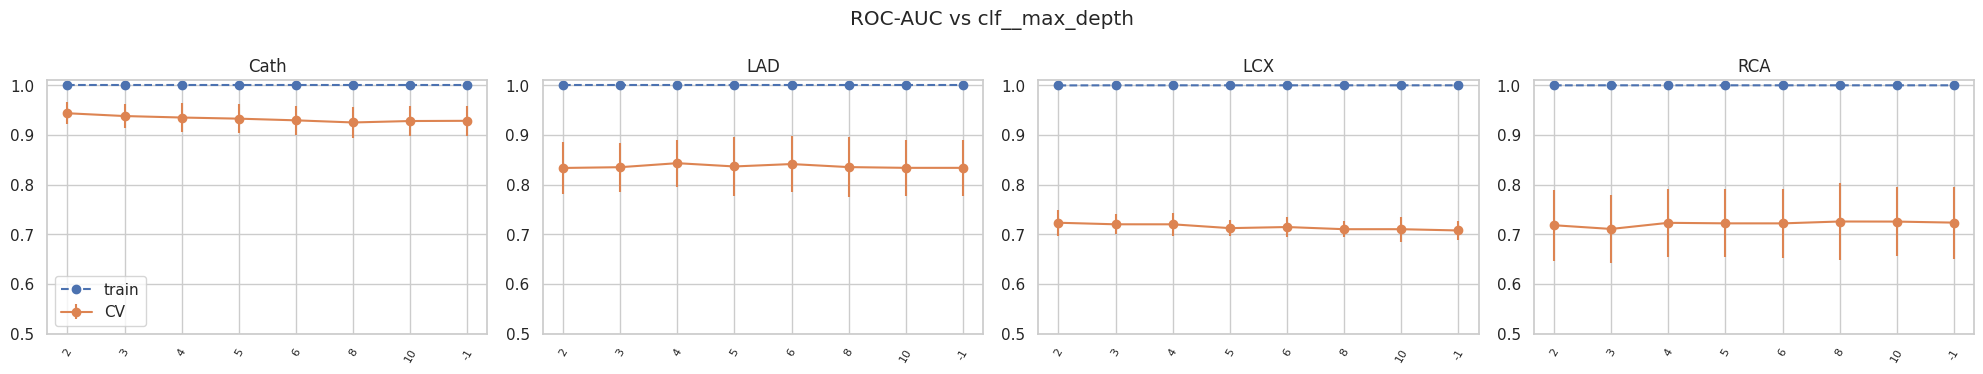

In [7]:
def sweep(param,values,title,fname):
    fig,axes=plt.subplots(1,4,figsize=(20,3.8)); out={}
    for ax,t in zip(axes,TARGETS):
        tr_s,cv_s=validation_curve(make_pipe(new_clf()),X_tr,Y_tr[t],param_name=param,param_range=values,cv=cv5,scoring='roc_auc',n_jobs=-1)
        xs=np.arange(len(values)); out[t]=pd.DataFrame({'value':[str(v) for v in values],'train_auc':tr_s.mean(1),'cv_auc':cv_s.mean(1),'cv_std':cv_s.std(1)})
        ax.plot(xs,tr_s.mean(1),'o--',label='train'); ax.errorbar(xs,cv_s.mean(1),cv_s.std(1),fmt='o-',label='CV')
        ax.set_xticks(xs); ax.set_xticklabels([str(v) for v in values],rotation=60,fontsize=8); ax.set_title(f'{t}'); ax.set_ylim(0.5,1.01)
    axes[0].legend(); fig.suptitle(title); plt.tight_layout(); plt.savefig(FIG/f'lgbm_{fname}.png',dpi=110); plt.show(); return out
p1,v1=('clf__max_depth', [2,3,4,5,6,8,10,-1])
sw1=sweep(p1,v1,f'ROC-AUC vs {p1}','sweep1')

In [8]:
pd.concat({t:sw1[t].set_index('value')[['train_auc','cv_auc']] for t in TARGETS},axis=1).round(3)

Cath              LAD              LCX              RCA       
      train_auc cv_auc train_auc cv_auc train_auc cv_auc train_auc cv_auc
value                                                                    
2           1.0  0.944       1.0  0.834       1.0  0.723       1.0  0.718
3           1.0  0.938       1.0  0.835       1.0  0.720       1.0  0.711
4           1.0  0.935       1.0  0.843       1.0  0.720       1.0  0.723
5           1.0  0.933       1.0  0.837       1.0  0.712       1.0  0.722
6           1.0  0.929       1.0  0.841       1.0  0.715       1.0  0.722
8           1.0  0.925       1.0  0.835       1.0  0.710       1.0  0.726
10          1.0  0.928       1.0  0.834       1.0  0.710       1.0  0.726
-1          1.0  0.929       1.0  0.834       1.0  0.708       1.0  0.724

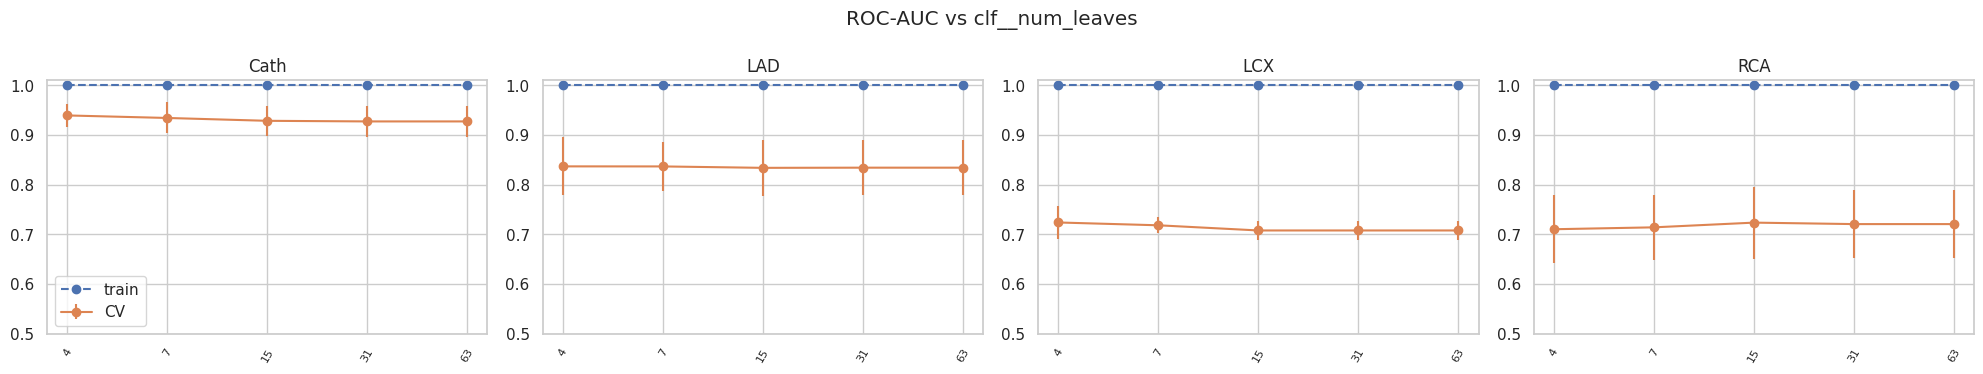

In [9]:
p2,v2=('clf__num_leaves', [4,7,15,31,63])
sw2=sweep(p2,v2,f'ROC-AUC vs {p2}','sweep2')

In [10]:
pd.concat({t:sw2[t].set_index('value')[['train_auc','cv_auc']] for t in TARGETS},axis=1).round(3)

Cath              LAD              LCX              RCA       
      train_auc cv_auc train_auc cv_auc train_auc cv_auc train_auc cv_auc
value                                                                    
4           1.0  0.939       1.0  0.837       1.0  0.724       1.0  0.710
7           1.0  0.934       1.0  0.837       1.0  0.718       1.0  0.714
15          1.0  0.929       1.0  0.834       1.0  0.708       1.0  0.724
31          1.0  0.927       1.0  0.834       1.0  0.708       1.0  0.721
63          1.0  0.927       1.0  0.834       1.0  0.708       1.0  0.721

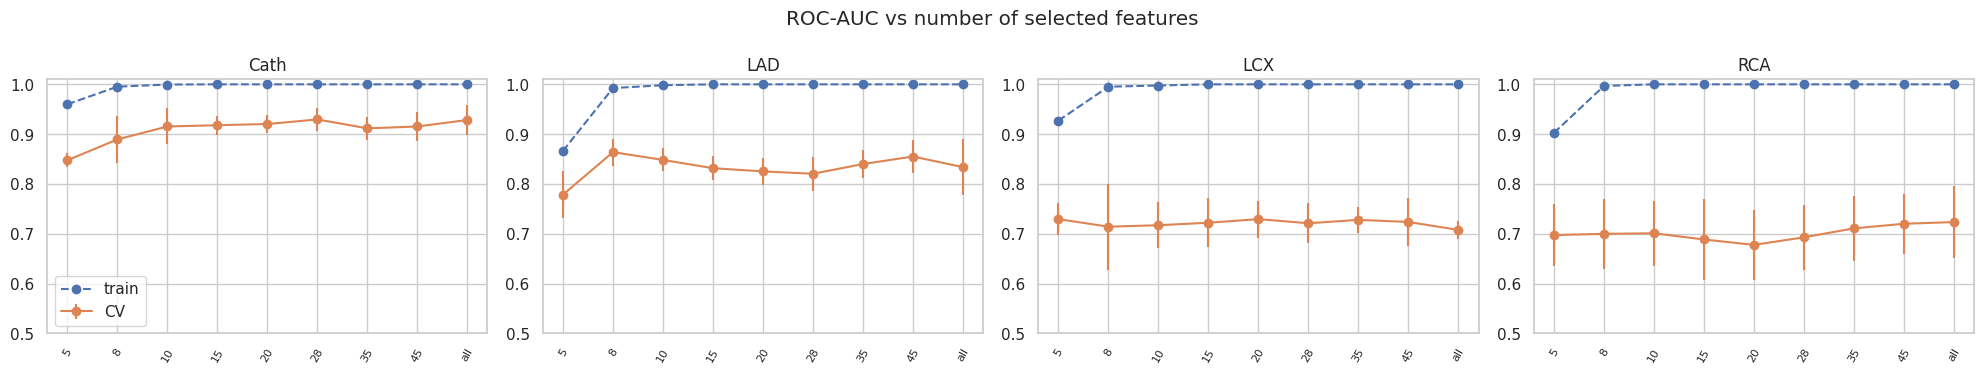

Cath              LAD              LCX              RCA       
      train_auc cv_auc train_auc cv_auc train_auc cv_auc train_auc cv_auc
value                                                                    
5         0.960  0.848     0.866  0.779     0.927  0.729     0.903  0.697
8         0.995  0.889     0.992  0.864     0.995  0.714     0.997  0.700
10        1.000  0.915     0.998  0.848     0.998  0.717     1.000  0.701
15        1.000  0.918     1.000  0.832     1.000  0.722     1.000  0.689
20        1.000  0.920     1.000  0.825     1.000  0.729     1.000  0.678
28        1.000  0.929     1.000  0.821     1.000  0.721     1.000  0.693
35        1.000  0.912     1.000  0.840     1.000  0.728     1.000  0.711
45        1.000  0.915     1.000  0.855     1.000  0.724     1.000  0.720
all       1.000  0.929     1.000  0.834     1.000  0.708     1.000  0.724

In [11]:
# number of selected features (SelectKBest inside the pipeline)
ks=[5,8,10,15,20,28,35,45,'all']
sw3=sweep('fs__k',ks,'ROC-AUC vs number of selected features','sweep_k')
pd.concat({t:sw3[t].set_index('value')[['train_auc','cv_auc']] for t in TARGETS},axis=1).round(3)

## 6. GridSearchCV (focused grid, 5×2 repeated CV, 5 metrics, refit on ROC-AUC)

In [12]:
def param_grid(spw):
    return {'fs__k':[20,'all'],'sampler':['passthrough',SMOTE(random_state=SEED)],'clf__max_depth':[3,5,-1],'clf__num_leaves':[7,15,31],
            'clf__learning_rate':[0.03,0.1],'clf__n_estimators':[150,400],'clf__min_child_samples':[5,15],'clf__class_weight':[None,'balanced']}
def param_space(spw):
    return {'fs__k':[10,15,20,28,35,45,'all'],'sampler':['passthrough',SMOTE(random_state=SEED)],'clf__max_depth':[-1,2,3,4,5,6,8,10],
            'clf__num_leaves':randint(4,64),'clf__learning_rate':loguniform(0.01,0.3),'clf__n_estimators':randint(80,700),
            'clf__min_child_samples':randint(3,30),'clf__subsample':uniform(0.5,0.5),'clf__colsample_bytree':uniform(0.4,0.6),
            'clf__reg_alpha':loguniform(1e-3,10),'clf__reg_lambda':loguniform(1e-2,30),'clf__class_weight':[None,'balanced']}
for t in TARGETS:
    g=param_grid(spw[t]); size=int(np.sum([np.prod([len(v) for v in d.values()]) for d in (g if isinstance(g,list) else [g])]))
    print(t,'grid combinations:',size,'-> fits:',size*10)

Cath grid combinations: 576 -> fits: 5760
LAD grid combinations: 576 -> fits: 5760
LCX grid combinations: 576 -> fits: 5760
RCA grid combinations: 576 -> fits: 5760


In [13]:
searches={t:{} for t in TARGETS}
for t in TARGETS:
    t0=time.time()
    gs=GridSearchCV(make_pipe(new_clf()),param_grid(spw[t]),scoring=SCORING,refit='roc_auc',cv=cv52,n_jobs=-1,verbose=0)
    gs.fit(X_tr,Y_tr[t]); searches[t]['grid']=gs
    pd.DataFrame(gs.cv_results_).to_csv(RES/f'{M}_cv_grid_{t}.csv',index=False)
    print(f'{t}: best CV AUC={gs.best_score_:.4f}  ({time.time()-t0:.0f}s, {len(gs.cv_results_["params"])} combos)')

Cath: best CV AUC=0.9459  (25s, 576 combos)


LAD: best CV AUC=0.8642  (24s, 576 combos)


LCX: best CV AUC=0.7217  (24s, 576 combos)


RCA: best CV AUC=0.7536  (24s, 576 combos)


## 7. RandomizedSearchCV (wide space, many more combinations)

In [14]:
N_ITER=250
for t in TARGETS:
    t0=time.time()
    rs=RandomizedSearchCV(make_pipe(new_clf()),param_space(spw[t]),n_iter=N_ITER,scoring=SCORING,refit='roc_auc',cv=cv52,n_jobs=-1,random_state=SEED,verbose=0)
    rs.fit(X_tr,Y_tr[t]); searches[t]['random']=rs
    pd.DataFrame(rs.cv_results_).to_csv(RES/f'{M}_cv_random_{t}.csv',index=False)
    print(f'{t}: best CV AUC={rs.best_score_:.4f}  ({time.time()-t0:.0f}s)')

Cath: best CV AUC=0.9501  (11s)


LAD: best CV AUC=0.8754  (11s)


LCX: best CV AUC=0.7337  (11s)


RCA: best CV AUC=0.7639  (11s)


## 8. Pick the best configuration per target

In [15]:
best_est,rows={},[]
for t in TARGETS:
    g,r=searches[t]['grid'],searches[t]['random']
    win,name=(g,'grid') if g.best_score_>=r.best_score_ else (r,'random')
    best_est[t]=win.best_estimator_; i=win.best_index_; cr=win.cv_results_
    rows.append({'target':t,'winner':name,'cv_roc_auc':cr['mean_test_roc_auc'][i],'cv_pr_auc':cr['mean_test_average_precision'][i],
                 'cv_bal_acc':cr['mean_test_balanced_accuracy'][i],'cv_f1':cr['mean_test_f1'][i],'cv_recall':cr['mean_test_recall'][i],
                 'grid_auc':g.best_score_,'random_auc':r.best_score_})
best_tbl=pd.DataFrame(rows).set_index('target').round(4); best_tbl

,winner,cv_roc_auc,cv_pr_auc,cv_bal_acc,cv_f1,cv_recall,grid_auc,random_auc
target,,,,,,,,
Cath,random,0.9501,0.9807,0.8426,0.9189,0.9335,0.9459,0.9501
LAD,random,0.8754,0.8956,0.7929,0.8327,0.8475,0.8642,0.8754
LCX,random,0.7337,0.6320,0.6474,0.5567,0.5374,0.7217,0.7337
RCA,random,0.7639,0.6445,0.7045,0.6356,0.6643,0.7536,0.7639


In [16]:
best_params=pd.DataFrame({t:{k:str(v) for k,v in best_est[t].get_params().items() if k.startswith(('clf__','fs__k','sampler'))
                                 and not isinstance(v,(dict,)) and k not in ('sampler__random_state',)} for t in TARGETS}); best_params

,Cath,LAD,LCX,RCA
sampler,SMOTE(random_state=42),passthrough,passthrough,SMOTE(random_state=42)
fs__k,all,10,35,45
sampler__k_neighbors,5,NaN,NaN,5
sampler__sampling_strategy,auto,NaN,NaN,auto
clf__boosting_type,gbdt,gbdt,gbdt,gbdt
clf__class_weight,None,None,balanced,None
clf__colsample_bytree,0.47749564909089703,0.6604116197043252,0.7934342035369938,0.4531333505339449
clf__importance_type,split,split,split,split
clf__learning_rate,0.25659550869174796,0.013516790352047638,0.1789049217851632,0.014210189070387708
clf__max_depth,5,4,2,3


In [17]:
# top-5 combinations per target (from both searches)
for t in TARGETS:
    parts=[]
    for nm in ('grid','random'):
        d=pd.DataFrame(searches[t][nm].cv_results_); d['search']=nm; parts.append(d)
    d=pd.concat(parts).sort_values('mean_test_roc_auc',ascending=False).head(5)
    print('==',t); print(d[['search','mean_test_roc_auc','std_test_roc_auc','mean_test_balanced_accuracy','mean_test_recall','params']].to_string(index=False,max_colwidth=160))

== Cath
search  mean_test_roc_auc  std_test_roc_auc  mean_test_balanced_accuracy  mean_test_recall                                                                                                                                                           params
random           0.950058          0.025855                     0.842589          0.933529 {'clf__class_weight': None, 'clf__colsample_bytree': 0.47749564909089703, 'clf__learning_rate': 0.25659550869174796, 'clf__max_depth': 5, 'clf__min_child_sam...
random           0.948335          0.022551                     0.844525          0.922017 {'clf__class_weight': 'balanced', 'clf__colsample_bytree': 0.495726808067913, 'clf__learning_rate': 0.19396797673534563, 'clf__max_depth': 2, 'clf__min_child...
random           0.947480          0.026776                     0.848012          0.936134 {'clf__class_weight': 'balanced', 'clf__colsample_bytree': 0.7819865929733696, 'clf__learning_rate': 0.06599787127341451, 'clf__max_depth': 3, 'c

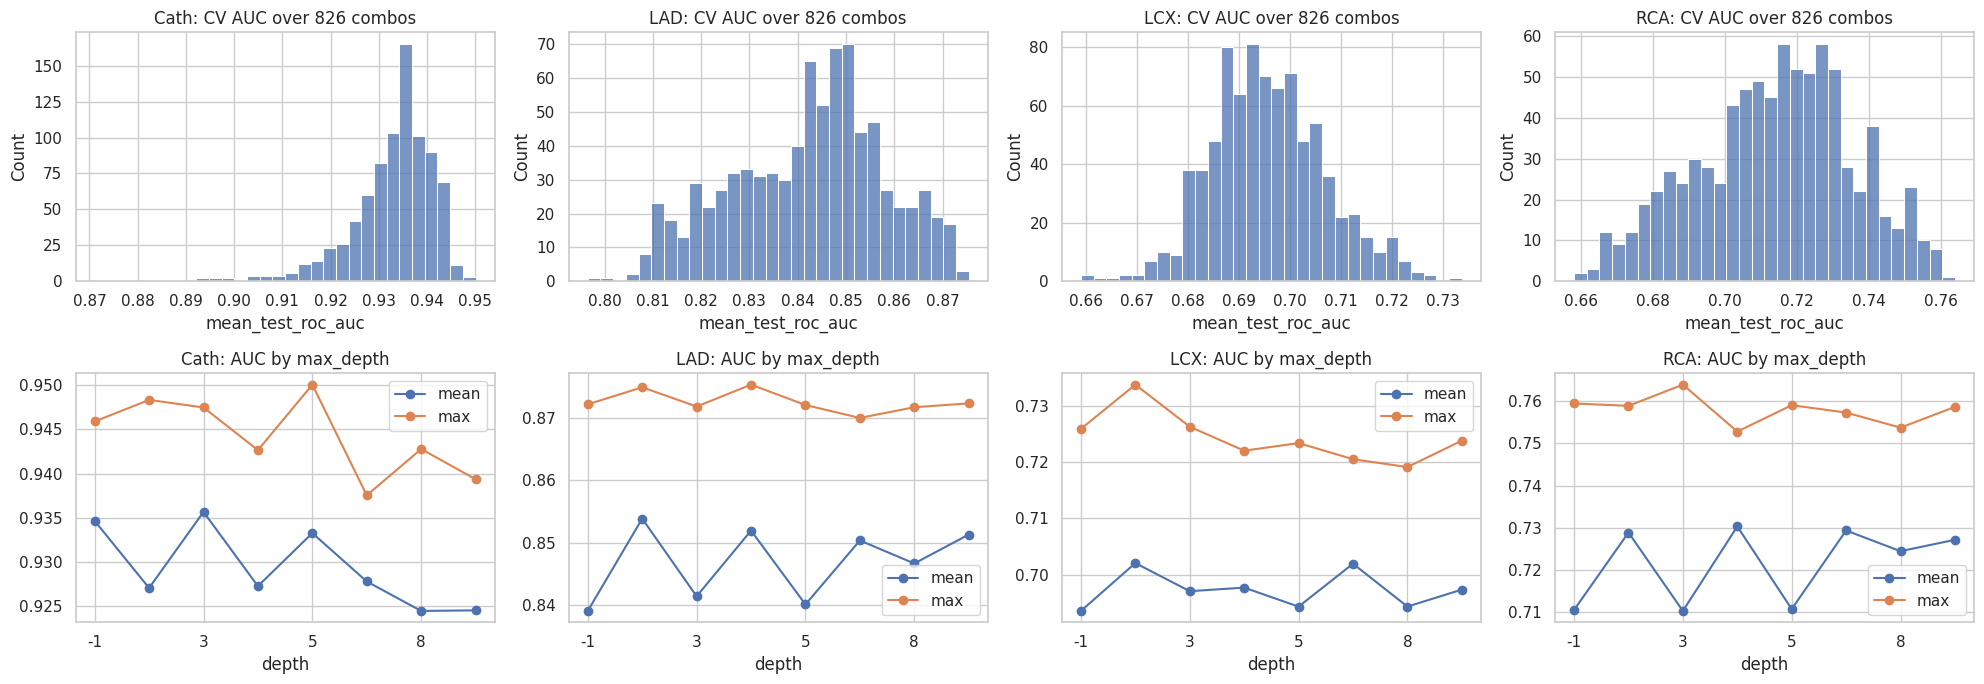

In [18]:
# distribution of CV AUC over all tried combinations + effect of depth if it was tuned
fig,axes=plt.subplots(2,4,figsize=(20,7))
for j,t in enumerate(TARGETS):
    d=pd.concat([pd.DataFrame(searches[t][n_].cv_results_) for n_ in ('grid','random')])
    sns.histplot(d.mean_test_roc_auc,bins=30,ax=axes[0,j]); axes[0,j].set_title(f'{t}: CV AUC over {len(d)} combos')
    col=[c for c in d.columns if c.endswith('max_depth')]
    if col:
        dd=d.assign(depth=d[col[0]].astype(str)).groupby('depth').mean_test_roc_auc.agg(['mean','max'])
        dd=dd.loc[sorted(dd.index,key=lambda s:(s=='None',float(s) if s not in ('None',) else 99))]
        dd.plot(ax=axes[1,j],marker='o'); axes[1,j].set_title(f'{t}: AUC by max_depth')
    else:
        d.assign(k=d['param_fs__k'].astype(str)).groupby('k').mean_test_roc_auc.max().plot.bar(ax=axes[1,j]); axes[1,j].set_title(f'{t}: best AUC by k')
plt.tight_layout(); plt.savefig(FIG/f'{M}_search_overview.png',dpi=110); plt.show()

## 9. Effect of the number of CV folds (best configuration, train only)

In [19]:
schemes={'3-fold':StratifiedKFold(3,shuffle=True,random_state=SEED),'5-fold':StratifiedKFold(5,shuffle=True,random_state=SEED),
         '7-fold':StratifiedKFold(7,shuffle=True,random_state=SEED),'10-fold':StratifiedKFold(10,shuffle=True,random_state=SEED),
         '5x3 repeated':RepeatedStratifiedKFold(n_splits=5,n_repeats=3,random_state=SEED),'10x3 repeated':RepeatedStratifiedKFold(n_splits=10,n_repeats=3,random_state=SEED)}
rows=[]
for t in TARGETS:
    for nm,cv in schemes.items():
        s=cross_validate(clone(best_est[t]),X_tr,Y_tr[t],cv=cv,scoring={'auc':'roc_auc','acc':'accuracy','bal':'balanced_accuracy'},n_jobs=-1)
        rows.append({'target':t,'cv':nm,'auc_mean':s['test_auc'].mean(),'auc_std':s['test_auc'].std(),'acc_mean':s['test_acc'].mean(),'bal_acc_mean':s['test_bal'].mean()})
fold_tbl=pd.DataFrame(rows); fold_tbl.to_csv(RES/f'{M}_cv_fold_study.csv',index=False)
fold_tbl.pivot(index='cv',columns='target',values='auc_mean').loc[list(schemes)].round(4)

target,Cath,LAD,LCX,RCA
cv,,,,
3-fold,0.9376,0.8641,0.6994,0.7423
5-fold,0.9397,0.8703,0.7534,0.7645
7-fold,0.9498,0.8663,0.7494,0.7924
10-fold,0.9565,0.8606,0.7691,0.7851
5x3 repeated,0.9496,0.8748,0.7309,0.7541
10x3 repeated,0.9503,0.8681,0.7439,0.7736


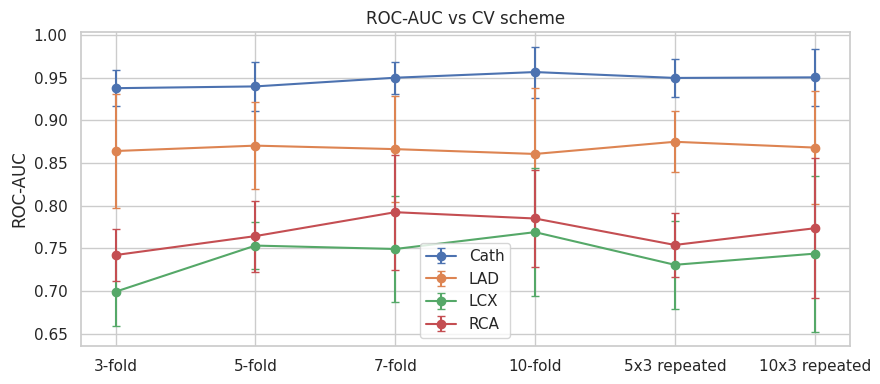

In [20]:
fig,ax=plt.subplots(figsize=(9,4))
for t in TARGETS:
    d=fold_tbl[fold_tbl.target==t]; ax.errorbar(range(len(d)),d.auc_mean,d.auc_std,marker='o',label=t,capsize=3)
ax.set_xticks(range(len(schemes))); ax.set_xticklabels(list(schemes)); ax.set_ylabel('ROC-AUC'); ax.legend(); ax.set_title('ROC-AUC vs CV scheme'); plt.tight_layout(); plt.show()

## 10. Nested CV on all 303 patients (paper-comparable protocol)
The paper reports 10-fold CV on all data. Here every outer fold tunes hyper-parameters (feature count, sampler, model parameters) on its own training part only, so the numbers are not tuned on the fold that scores them. Threshold = 0.5.

In [21]:
spec_scorer=make_scorer(recall_score,pos_label=0)
NEST_SCORING={'accuracy':'accuracy','balanced_acc':'balanced_accuracy','sensitivity':'recall','specificity':spec_scorer,'precision':'precision','f1':'f1','roc_auc':'roc_auc'}
outer=StratifiedKFold(10,shuffle=True,random_state=SEED); nested_rows=[]
for t in TARGETS:
    t0=time.time()
    inner=RandomizedSearchCV(make_pipe(new_clf()),param_space(spw[t]),n_iter=25,scoring='roc_auc',cv=StratifiedKFold(3,shuffle=True,random_state=SEED),n_jobs=1,random_state=SEED)
    r=cross_validate(inner,X_all,Y_all[t],cv=outer,scoring=NEST_SCORING,n_jobs=-1)
    row={'target':t}; row.update({k.replace('test_',''):r[k].mean() for k in r if k.startswith('test_')}); row.update({k.replace('test_','')+'_std':r[k].std() for k in r if k.startswith('test_')})
    nested_rows.append(row); print(t,f"acc={row['accuracy']:.3f} sens={row['sensitivity']:.3f} spec={row['specificity']:.3f} auc={row['roc_auc']:.3f} ({time.time()-t0:.0f}s)")
nested=pd.DataFrame(nested_rows).set_index('target'); nested.to_csv(RES/f'{M}_nested_cv.csv'); nested[[c for c in nested if not c.endswith('_std')]].round(4)

Cath acc=0.855 sens=0.912 spec=0.711 auc=0.935 (4s)


LAD acc=0.780 sens=0.847 spec=0.684 auc=0.849 (4s)


LCX acc=0.631 sens=0.462 spec=0.739 auc=0.679 (4s)


RCA acc=0.679 sens=0.527 spec=0.773 auc=0.710 (4s)


,accuracy,balanced_acc,sensitivity,specificity,precision,f1,roc_auc
target,,,,,,,
Cath,0.8551,0.8115,0.9119,0.7111,0.8949,0.8998,0.9349
LAD,0.7796,0.7655,0.8471,0.6840,0.7944,0.8174,0.8489
LCX,0.6314,0.6008,0.4621,0.7395,0.5371,0.4887,0.6787
RCA,0.6795,0.6497,0.5265,0.7728,0.5982,0.5522,0.7099


## 11. Decision threshold from out-of-fold *train* probabilities

In [22]:
def oof_proba(est,X,y,seeds=(0,1,2)):
    P=np.zeros(len(y))
    for s in seeds: P+=cross_val_predict(clone(est),X,y,cv=StratifiedKFold(5,shuffle=True,random_state=s),method='predict_proba',n_jobs=-1)[:,1]
    return P/len(seeds)
oof={t:oof_proba(best_est[t],X_tr,Y_tr[t]) for t in TARGETS}
THR={t:{'default_0.5':0.5,'youden':thr_youden(Y_tr[t],oof[t]),'sens>=0.95':thr_sens(Y_tr[t],oof[t],0.95)} for t in TARGETS}
pd.DataFrame(THR).T.round(3)

,default_0.5,youden,sens>=0.95
Cath,0.5,0.700,0.576
LAD,0.5,0.564,0.339
LCX,0.5,0.290,0.014
RCA,0.5,0.488,0.339


In [23]:
pd.DataFrame({(t,k):metrics_at(Y_tr[t],oof[t],v) for t in TARGETS for k,v in THR[t].items()}).T[['threshold','accuracy','sensitivity','specificity','roc_auc']].round(3)

threshold  accuracy  sensitivity  specificity  roc_auc
Cath default_0.5      0.500     0.913        0.960        0.797    0.955
     youden           0.700     0.901        0.902        0.899    0.955
     sens>=0.95       0.576     0.913        0.954        0.812    0.955
LAD  default_0.5      0.500     0.818        0.872        0.743    0.869
     youden           0.564     0.826        0.851        0.792    0.869
     sens>=0.95       0.339     0.789        0.950        0.564    0.869
LCX  default_0.5      0.500     0.686        0.532        0.784    0.745
     youden           0.290     0.707        0.755        0.676    0.745
     sens>=0.95       0.014     0.566        0.957        0.318    0.745
RCA  default_0.5      0.500     0.711        0.670        0.735    0.759
     youden           0.488     0.715        0.725        0.709    0.759
     sens>=0.95       0.339     0.607        0.956        0.397    0.759

## 12. Final evaluation on the held-out test set (touched once)

In [24]:
test_proba={}
for t in TARGETS:
    best_est[t].fit(X_tr,Y_tr[t]); test_proba[t]=best_est[t].predict_proba(X_te)[:,1]
rows=[]
for t in TARGETS:
    for k,thr in THR[t].items():
        m=metrics_at(Y_te[t],test_proba[t],thr); (alo,ahi),(clo,chi)=boot_ci(Y_te[t],test_proba[t],thr)
        rows.append({'target':t,'strategy':'direct','threshold_rule':k,**m,'auc_ci':f'[{alo:.3f},{ahi:.3f}]','acc_ci':f'[{clo:.3f},{chi:.3f}]'})
test_tbl=pd.DataFrame(rows); test_tbl.to_csv(RES/f'{M}_test_metrics_direct.csv',index=False)
test_tbl[['target','threshold_rule','threshold','accuracy','balanced_acc','sensitivity','specificity','precision','f1','roc_auc','pr_auc','brier','auc_ci','acc_ci']].round(3)

,target,threshold_rule,threshold,accuracy,balanced_acc,sensitivity,specificity,precision,f1,roc_auc,pr_auc,brier,auc_ci,acc_ci
0,Cath,default_0.5,0.500,0.820,0.731,0.932,0.529,0.837,0.882,0.916,0.967,0.129,"[0.830,0.982]","[0.721,0.918]"
1,Cath,youden,0.700,0.820,0.749,0.909,0.588,0.851,0.879,0.916,0.967,0.129,"[0.830,0.982]","[0.721,0.918]"
2,Cath,sens>=0.95,0.576,0.836,0.760,0.932,0.588,0.854,0.891,0.916,0.967,0.129,"[0.830,0.982]","[0.738,0.918]"
3,LAD,default_0.5,0.500,0.721,0.697,0.833,0.560,0.732,0.779,0.787,0.841,0.187,"[0.667,0.898]","[0.606,0.820]"
4,LAD,youden,0.564,0.705,0.689,0.778,0.600,0.737,0.757,0.787,0.841,0.187,"[0.667,0.898]","[0.590,0.820]"
5,LAD,sens>=0.95,0.339,0.770,0.726,0.972,0.480,0.729,0.833,0.787,0.841,0.187,"[0.667,0.898]","[0.672,0.869]"
6,LCX,default_0.5,0.500,0.689,0.681,0.640,0.722,0.615,0.627,0.723,0.589,0.261,"[0.584,0.841]","[0.574,0.803]"
7,LCX,youden,0.290,0.656,0.672,0.760,0.583,0.559,0.644,0.723,0.589,0.261,"[0.584,0.841]","[0.541,0.771]"
8,LCX,sens>=0.95,0.014,0.590,0.641,0.920,0.361,0.500,0.648,0.723,0.589,0.261,"[0.584,0.841]","[0.475,0.721]"
9,RCA,default_0.5,0.500,0.541,0.537,0.522,0.553,0.414,0.462,0.659,0.567,0.226,"[0.506,0.793]","[0.426,0.672]"


In [25]:
# majority-class reference on the same test set
pd.DataFrame({t:{'majority-class accuracy':max(Y_te[t].mean(),1-Y_te[t].mean()),'model accuracy (youden)':test_tbl[(test_tbl.target==t)&(test_tbl.threshold_rule=='youden')].accuracy.iloc[0]} for t in TARGETS}).T.round(3)

,majority-class accuracy,model accuracy (youden)
Cath,0.721,0.820
LAD,0.590,0.705
LCX,0.590,0.656
RCA,0.623,0.541


## 13. Curves and confusion matrices

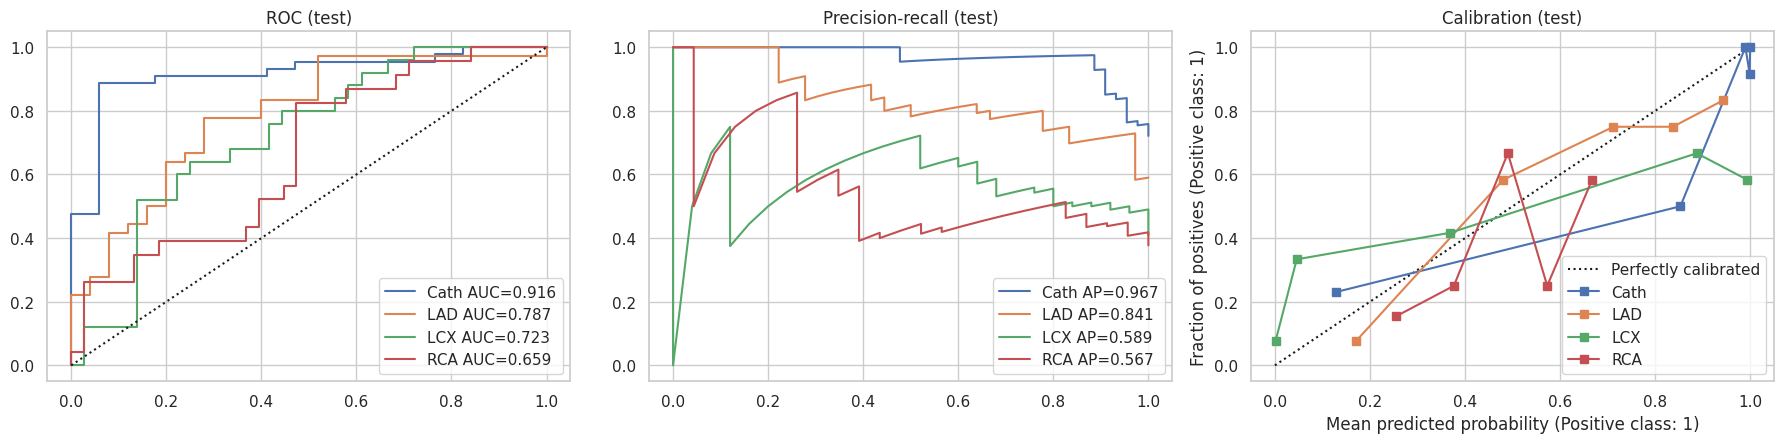

In [26]:
fig,axes=plt.subplots(1,3,figsize=(18,4.6))
for t in TARGETS:
    f,s,_=roc_curve(Y_te[t],test_proba[t]); axes[0].plot(f,s,label=f'{t} AUC={roc_auc_score(Y_te[t],test_proba[t]):.3f}')
    p,r,_=precision_recall_curve(Y_te[t],test_proba[t]); axes[1].plot(r,p,label=f'{t} AP={average_precision_score(Y_te[t],test_proba[t]):.3f}')
    CalibrationDisplay.from_predictions(Y_te[t],test_proba[t],n_bins=5,strategy='quantile',ax=axes[2],name=t)
axes[0].plot([0,1],[0,1],'k:'); axes[0].set_title('ROC (test)'); axes[1].set_title('Precision-recall (test)'); axes[2].set_title('Calibration (test)')
for a in axes[:2]: a.legend()
plt.tight_layout(); plt.savefig(FIG/f'{M}_curves.png',dpi=110); plt.show()

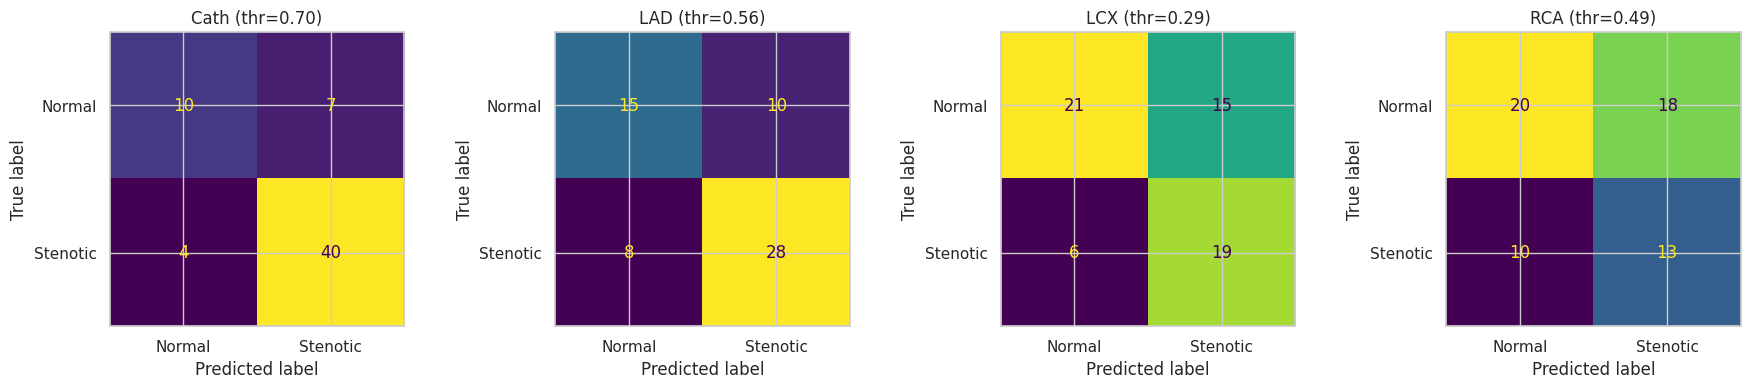

In [27]:
fig,axes=plt.subplots(1,4,figsize=(18,4))
for ax,t in zip(axes,TARGETS):
    thr=THR[t]['youden']; ConfusionMatrixDisplay.from_predictions(Y_te[t],(test_proba[t]>=thr).astype(int),ax=ax,colorbar=False,display_labels=['Normal','Stenotic']); ax.set_title(f'{t} (thr={thr:.2f})')
plt.tight_layout(); plt.savefig(FIG/f'{M}_confusion.png',dpi=110); plt.show()

## 14. Paper methods on this model family
1. **Single classifier** – Cath model only (section 12).
2. **Three-classifier OR rule** – `CT = LAD ∨ LCX ∨ RCA` (Eq. 1 of the paper).
3. **Feature-engineering (stacked) method** – out-of-fold probabilities of the LAD/LCX/RCA/CAD models are appended to the clinical features and a final CAD classifier is trained on them. Train probabilities are out-of-fold, test probabilities come from models fitted on the full train set.

In [28]:
# 2) OR rule
rows=[]
for rule in ('default_0.5','youden'):
    pred=np.zeros(len(te),int)
    for t in ['LAD','LCX','RCA']: pred|=(test_proba[t]>=THR[t][rule]).astype(int)
    score=1-np.prod([1-test_proba[t] for t in ['LAD','LCX','RCA']],axis=0)               # P(at least one stenotic), independence assumption
    yh=pred; tn,fp,fn,tp=confusion_matrix(Y_te['Cath'],yh,labels=[0,1]).ravel()
    rows.append({'target':'Cath','strategy':'OR-rule','threshold_rule':rule,'accuracy':accuracy_score(Y_te['Cath'],yh),'balanced_acc':balanced_accuracy_score(Y_te['Cath'],yh),
                 'sensitivity':tp/(tp+fn),'specificity':tn/(tn+fp),'precision':precision_score(Y_te['Cath'],yh,zero_division=0),'f1':f1_score(Y_te['Cath'],yh),
                 'roc_auc':roc_auc_score(Y_te['Cath'],score),'pr_auc':average_precision_score(Y_te['Cath'],score),'brier':brier_score_loss(Y_te['Cath'],score),'TP':tp,'FP':fp,'TN':tn,'FN':fn})
or_tbl=pd.DataFrame(rows); or_tbl.round(3)

,target,strategy,threshold_rule,accuracy,balanced_acc,sensitivity,specificity,precision,f1,roc_auc,pr_auc,brier,TP,FP,TN,FN
0,Cath,OR-rule,default_0.5,0.852,0.826,0.886,0.765,0.907,0.897,0.861,0.921,0.125,39,4,13,5
1,Cath,OR-rule,youden,0.820,0.785,0.864,0.706,0.884,0.874,0.861,0.921,0.125,38,5,12,6


In [29]:
# 3) stacked method
PCOLS=['p_LAD','p_LCX','p_RCA','p_CAD']
oof_tr={t:cross_val_predict(clone(best_est[t]),X_tr,Y_tr[t],cv=StratifiedKFold(5,shuffle=True,random_state=SEED),method='predict_proba',n_jobs=-1)[:,1] for t in TARGETS}
def augment(X,P):
    A=X.copy()
    for c,t in zip(PCOLS,['LAD','LCX','RCA','Cath']): A[c]=P[t]
    return A
Xa_tr=augment(X_tr,oof_tr); Xa_te=augment(X_te,test_proba)
def meta_pipe():
    p=clone(best_est['Cath']); p.set_params(prep=ColumnTransformer([('base',build_preprocessor(),FEATURES),('probs','passthrough',PCOLS)],verbose_feature_names_out=False))
    return p
mg=GridSearchCV(meta_pipe(),{'fs__k':[4,8,12,20,32,'all'],'sampler':['passthrough',SMOTE(random_state=SEED)]},scoring='roc_auc',cv=cv52,n_jobs=-1).fit(Xa_tr,Y_tr['Cath'])
meta=mg.best_estimator_; print('stacked CV AUC:',round(mg.best_score_,4),'| params:',{k:v for k,v in mg.best_params_.items()})
oof_meta=oof_proba(meta,Xa_tr,Y_tr['Cath']); thr_meta={'default_0.5':0.5,'youden':thr_youden(Y_tr['Cath'],oof_meta),'sens>=0.95':thr_sens(Y_tr['Cath'],oof_meta,0.95)}
meta.fit(Xa_tr,Y_tr['Cath']); p_meta=meta.predict_proba(Xa_te)[:,1]
st=pd.DataFrame([{'target':'Cath','strategy':'stacked (paper FE)','threshold_rule':k,**metrics_at(Y_te['Cath'],p_meta,v)} for k,v in thr_meta.items()]); st.round(3)

stacked CV AUC: 0.9293 | params: {'fs__k': 'all', 'sampler': SMOTE(random_state=42)}


,target,strategy,threshold_rule,threshold,accuracy,balanced_acc,sensitivity,specificity,precision,f1,roc_auc,pr_auc,brier,TP,FP,TN,FN
0,Cath,stacked (paper FE),default_0.5,0.500,0.852,0.807,0.909,0.706,0.889,0.899,0.913,0.963,0.125,40,5,12,4
1,Cath,stacked (paper FE),youden,0.842,0.869,0.855,0.886,0.824,0.929,0.907,0.913,0.963,0.125,39,3,14,5
2,Cath,stacked (paper FE),sens>=0.95,0.189,0.836,0.778,0.909,0.647,0.870,0.889,0.913,0.963,0.125,40,6,11,4


In [30]:
# compare the three strategies for CAD with the paper's SVM numbers (10-fold CV on 500 patients; ours: held-out test of 61)
paper=pd.DataFrame([{'strategy':'PAPER single (SVM)','accuracy':.850,'sensitivity':.894,'specificity':.768,'roc_auc':.81},
                    {'strategy':'PAPER three-classifier (SVM)','accuracy':.810,'sensitivity':.814,'specificity':.798,'roc_auc':.87},
                    {'strategy':'PAPER feature engineering (SVM)','accuracy':.964,'sensitivity':1.0,'specificity':.881,'roc_auc':.92}])
ours=pd.concat([test_tbl[test_tbl.target=='Cath'].assign(strategy=lambda d:'direct @'+d.threshold_rule),or_tbl.assign(strategy=lambda d:'OR-rule @'+d.threshold_rule),
                st.assign(strategy=lambda d:'stacked @'+d.threshold_rule)])[['strategy','accuracy','sensitivity','specificity','roc_auc']]
cmp_tbl=pd.concat([paper,ours.assign(strategy=lambda d:'OURS '+M+' '+d.strategy)]).set_index('strategy'); cmp_tbl.round(3)

,accuracy,sensitivity,specificity,roc_auc
strategy,,,,
PAPER single (SVM),0.850,0.894,0.768,0.810
PAPER three-classifier (SVM),0.810,0.814,0.798,0.870
PAPER feature engineering (SVM),0.964,1.000,0.881,0.920
OURS lgbm direct @default_0.5,0.820,0.932,0.529,0.916
OURS lgbm direct @youden,0.820,0.909,0.588,0.916
OURS lgbm direct @sens>=0.95,0.836,0.932,0.588,0.916
OURS lgbm OR-rule @default_0.5,0.852,0.886,0.765,0.861
OURS lgbm OR-rule @youden,0.820,0.864,0.706,0.861
OURS lgbm stacked @default_0.5,0.852,0.909,0.706,0.913


In [31]:
all_rows=pd.concat([test_tbl,or_tbl,st]); all_rows.to_csv(RES/f'{M}_test_metrics.csv',index=False)
nested.loc[['Cath']].round(3).rename(index={'Cath':'OURS nested 10-fold CV (303 pts, thr 0.5)'})[['accuracy','sensitivity','specificity','roc_auc']]

,accuracy,sensitivity,specificity,roc_auc
target,,,,
"OURS nested 10-fold CV (303 pts, thr 0.5)",0.855,0.912,0.711,0.935


## 15. Permutation importance on the test set (raw features, per target)

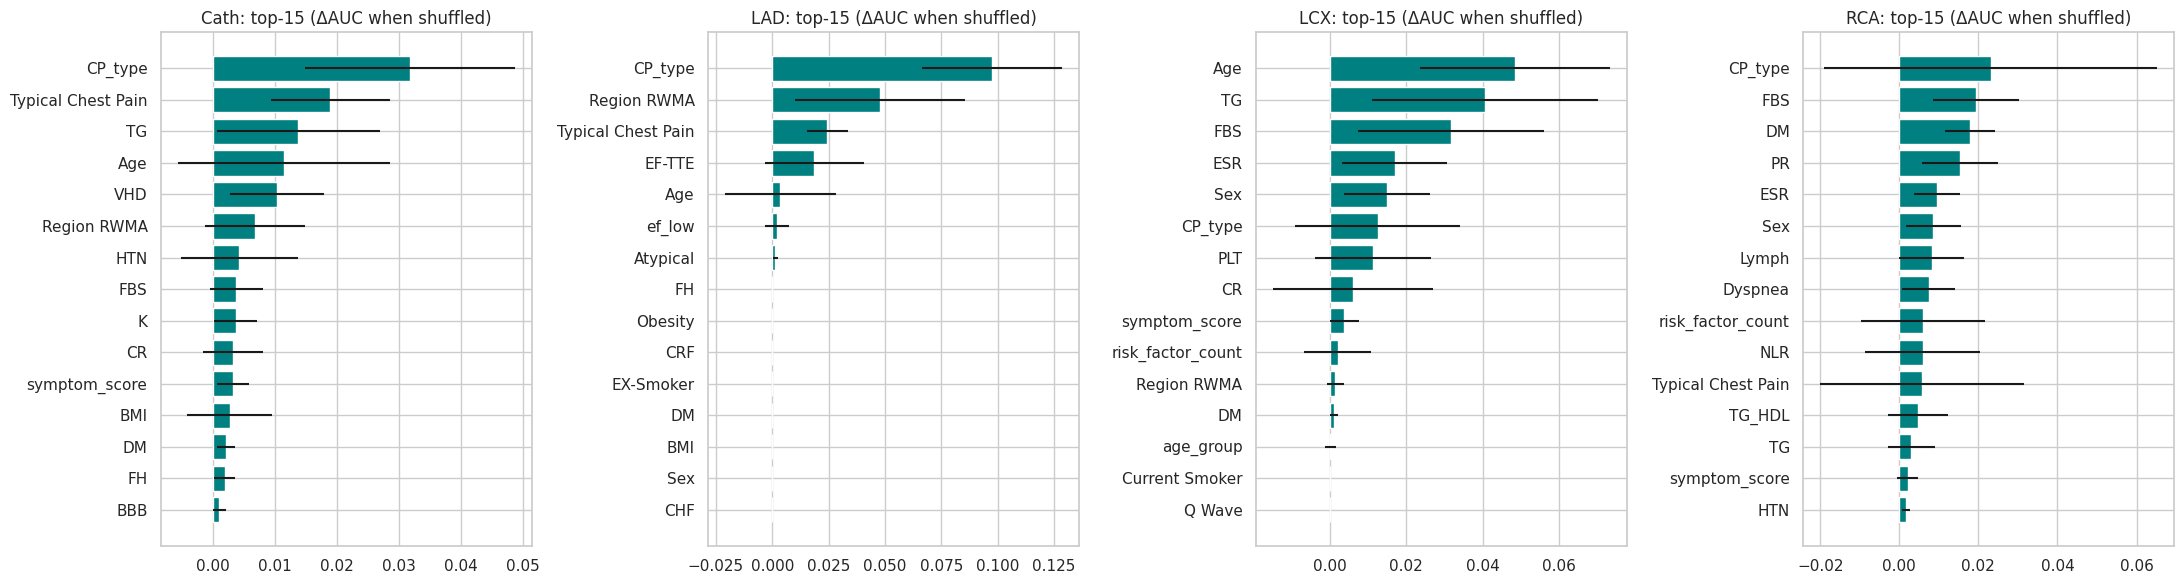

In [32]:
imp={}
for t in TARGETS:
    r=permutation_importance(best_est[t],X_te,Y_te[t],scoring='roc_auc',n_repeats=30,random_state=SEED,n_jobs=-1)
    imp[t]=pd.DataFrame({'importance':r.importances_mean,'std':r.importances_std},index=FEATURES).sort_values('importance',ascending=False)
    imp[t].to_csv(RES/f'{M}_perm_importance_{t}.csv')
fig,axes=plt.subplots(1,4,figsize=(22,6))
for ax,t in zip(axes,TARGETS):
    d=imp[t].head(15)[::-1]; ax.barh(d.index,d.importance,xerr=d['std'],color='teal'); ax.set_title(f'{t}: top-15 (ΔAUC when shuffled)')
plt.tight_layout(); plt.savefig(FIG/f'{M}_perm_importance.png',dpi=110); plt.show()

In [33]:
pd.concat({t:imp[t].head(10).importance.round(4).reset_index().rename(columns={'index':'feature'}) for t in TARGETS},axis=1)

Cath                            LAD                           LCX                           RCA           
              feature importance             feature importance            feature importance            feature importance
0             CP_type     0.0318             CP_type     0.0976                Age     0.0484            CP_type     0.0232
1  Typical Chest Pain     0.0189         Region RWMA     0.0477                 TG     0.0406                FBS     0.0195
2                  TG     0.0138  Typical Chest Pain     0.0245                FBS     0.0316                 DM     0.0179
3                 Age     0.0115              EF-TTE     0.0187                ESR     0.0170                 PR     0.0154
4                 VHD     0.0104                 Age     0.0036                Sex     0.0149                ESR     0.0095
5         Region RWMA     0.0068              ef_low     0.0023            CP_type     0.0125                Sex     0.0086
6                 HTN     0.0043            Atypical     0.0013                PLT     0.0113              Lymph     0.0082
7                 FBS     0.0038                  FH     0.0000                 CR     0.0060            Dyspnea     0.0074
8                   K     0.0037             Obesity     0.0000      symptom_score     0.0038  risk_factor_count     0.0059
9                  CR     0.0033                 CRF     0.0000  risk_factor_count     0.0020                NLR     0.0059

## 16. Save fitted pipelines and probabilities

In [34]:
for t in TARGETS: joblib.dump(best_est[t],MOD/f'{M}_{t}.joblib')
joblib.dump(meta,MOD/f'{M}_stacked_Cath.joblib')
pd.DataFrame({t:test_proba[t] for t in TARGETS}|{'stacked_Cath':p_meta,'patient_idx':te.patient_idx.values}).to_csv(RES/f'{M}_test_proba.csv',index=False)
pd.DataFrame({t:oof[t] for t in TARGETS}|{'patient_idx':tr.patient_idx.values}).to_csv(RES/f'{M}_oof_train_proba.csv',index=False)
best_tbl.to_csv(RES/f'{M}_best_cv_summary.csv'); best_params.to_csv(RES/f'{M}_best_params.csv'); baseline.to_csv(RES/f'{M}_baseline.csv')
print('saved:',sorted(p.name for p in RES.glob(f'{M}_*'))[:30])

saved: ['lgbm_baseline.csv', 'lgbm_best_cv_summary.csv', 'lgbm_best_params.csv', 'lgbm_cv_fold_study.csv', 'lgbm_cv_grid_Cath.csv', 'lgbm_cv_grid_LAD.csv', 'lgbm_cv_grid_LCX.csv', 'lgbm_cv_grid_RCA.csv', 'lgbm_cv_random_Cath.csv', 'lgbm_cv_random_LAD.csv', 'lgbm_cv_random_LCX.csv', 'lgbm_cv_random_RCA.csv', 'lgbm_nested_cv.csv', 'lgbm_oof_train_proba.csv', 'lgbm_perm_importance_Cath.csv', 'lgbm_perm_importance_LAD.csv', 'lgbm_perm_importance_LCX.csv', 'lgbm_perm_importance_RCA.csv', 'lgbm_test_metrics.csv', 'lgbm_test_metrics_direct.csv', 'lgbm_test_proba.csv']


## 17. Summary

In [35]:
summary=test_tbl[test_tbl.threshold_rule=='youden'].set_index('target')[['accuracy','balanced_acc','sensitivity','specificity','precision','f1','roc_auc','pr_auc']].round(3)
summary.loc['Cath (stacked)']=st[st.threshold_rule=='youden'][['accuracy','balanced_acc','sensitivity','specificity','precision','f1','roc_auc','pr_auc']].iloc[0].round(3)
summary

,accuracy,balanced_acc,sensitivity,specificity,precision,f1,roc_auc,pr_auc
target,,,,,,,,
Cath,0.820,0.749,0.909,0.588,0.851,0.879,0.916,0.967
LAD,0.705,0.689,0.778,0.600,0.737,0.757,0.787,0.841
LCX,0.656,0.672,0.760,0.583,0.559,0.644,0.723,0.589
RCA,0.541,0.546,0.565,0.526,0.419,0.481,0.659,0.567
Cath (stacked),0.869,0.855,0.886,0.824,0.929,0.907,0.913,0.963
